In [ ]:
!pip install -q shap

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import shap

from tensorflow.keras import layers, models, datasets
from keras.preprocessing.image import load_img, img_to_array
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import resample, shuffle

from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dense, Dropout, Flatten, BatchNormalization

import requests
import zipfile
from typing import Literal

In [ ]:
# Criar a pasta para armazenar o dataset
folder = "/content/fer2013"
os.makedirs(folder, exist_ok=True)

# URL do dataset no Kaggle
url = "https://www.kaggle.com/api/v1/datasets/download/msambare/fer2013"

# Baixar o arquivo ZIP
response = requests.get(url, stream=True)
response.raise_for_status()

zip_file = f"{folder}/fer2013.zip"

with open(zip_file, "wb") as file_:
    for block in response.iter_content(chunk_size=1024 * 1024):
        if block:
            file_.write(block)

print("Download concluído!")

Download concluído!


In [ ]:
# Descompactar arquivo ZIP
with zipfile.ZipFile("/content/fer2013/fer2013.zip", "r") as file_:
    file_.extractall("/content/fer2013")

print("Dataset extraído com sucesso!")

for root, folders, felis in os.walk("/content/fer2013"):
    level = root.replace("/content/fer2013", "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

Dataset extraído com sucesso!
fer2013/
  train/
    happy/
    fear/
    sad/
    surprise/
    neutral/
    angry/
    disgust/
  test/
    happy/
    fear/
    sad/
    surprise/
    neutral/
    angry/
    disgust/


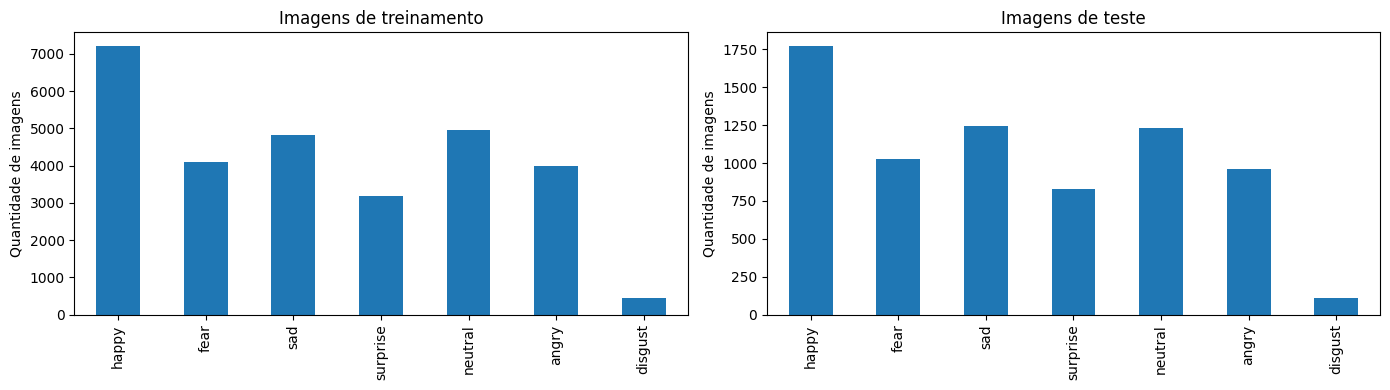

Imagens de treinamento: {'happy': 7215, 'fear': 4097, 'sad': 4830, 'surprise': 3171, 'neutral': 4965, 'angry': 3995, 'disgust': 436}
Imagens de teste: {'happy': 1774, 'fear': 1024, 'sad': 1247, 'surprise': 831, 'neutral': 1233, 'angry': 958, 'disgust': 111}


In [ ]:
train_dir = '/content/fer2013/train/'
test_dir = '/content/fer2013/test/'

# Contar imagens de treinamento
train_count = {class_: len(os.listdir(os.path.join(train_dir, class_)))
               for class_ in os.listdir(train_dir)}

# Contar imagens de teste
test_count = {class_: len(os.listdir(os.path.join(test_dir, class_)))
              for class_ in os.listdir(test_dir)}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(train_count).plot(kind="bar", ax=axes[0], title="Imagens de treinamento")
pd.Series(test_count).plot(kind="bar", ax=axes[1], title="Imagens de teste")
axes[0].set_ylabel("Quantidade de imagens")
axes[1].set_ylabel("Quantidade de imagens")
plt.tight_layout()
plt.show()

print("Imagens de treinamento:", train_count)
print("Imagens de teste:", test_count)


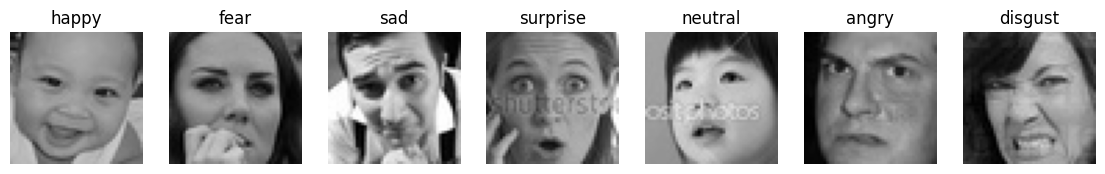

In [ ]:
plt.figure(figsize=(14,4))
i = 1
for expression in os.listdir(train_dir):
    img = load_img((train_dir + expression +'/'+ os.listdir(train_dir + expression)[5]))
    plt.subplot(1,7,i)
    plt.imshow(img)
    plt.title(expression)
    plt.axis('off')
    i += 1
plt.show()

In [ ]:
# Carregar os conjuntos de treino e teste
def carregar_imagens(path_dir):
    imagens = []
    rotulos = []
    mapping = {
    'angry': 0, 'disgust': 1, 'fear': 2,
    'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6
}
    for emocao, rotulo in mapping.items():
        pasta = os.path.join(path_dir, emocao)
        for arquivo in os.listdir(pasta):
            caminho = os.path.join(pasta, arquivo)
            if os.path.isfile(caminho):
                  imagem = load_img(caminho, target_size=(48, 48), color_mode="grayscale")
                  imagens.append(img_to_array(imagem))
                  rotulos.append(rotulo)
    return np.array(imagens, dtype=np.float32) / 255.0, np.array(rotulos, dtype=np.int32)

X_train_dataset, y_train_dataset = carregar_imagens(train_dir)
X_test, y_test = carregar_imagens(test_dir)


print("Imagens para treinamento:", len(X_train_dataset))
print("Imagens para teste:", len(X_test))

Imagens para treinamento: 28709
Imagens para teste: 7178


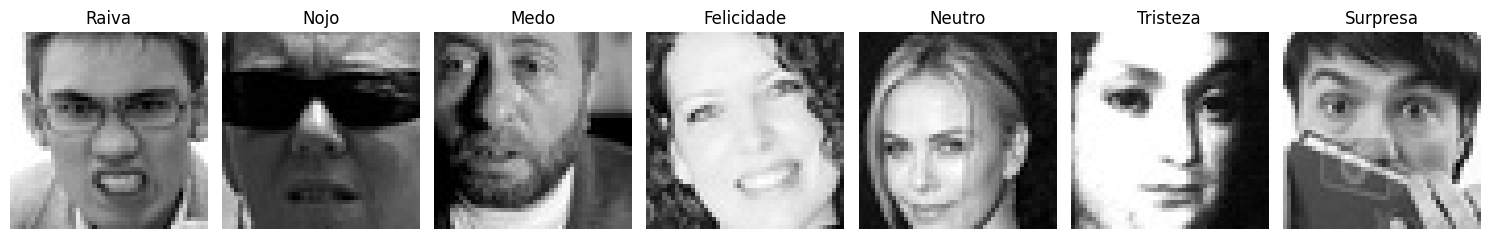

In [ ]:
classes = ['Raiva', 'Nojo', 'Medo', 'Felicidade', 'Neutro', 'Tristeza', 'Surpresa']

first_image_index = {}
for i, label in enumerate(y_train_dataset):
    first_image_index.setdefault(label, i)

fig, axes = plt.subplots(1, 7, figsize=(15, 4))

for i, ax in enumerate(axes):
    ax.imshow(X_train_dataset[first_image_index[i]].reshape(48, 48), cmap='gray')
    ax.set_title(classes[i])
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
X_train_dataset_shuffle, y_train_dataset_shuffle = shuffle(X_train_dataset, y_train_dataset, random_state=2)

# Separar treinamento e validação mantendo a proporção das classes
X_train, X_val, y_train, y_val = train_test_split(
    X_train_dataset_shuffle, y_train_dataset_shuffle, test_size=0.2, random_state=42, stratify=y_train_dataset
)
print("Imagens para treinamento:", len(X_train))
train_count = {class_: len(np.where(y_train == i)[0]) for i, class_ in enumerate(classes)}
print("Imagens de treinamento por classe:", train_count)
print("Imagens para validação:", len(X_val))
val_count = {class_: len(np.where(y_val == i)[0]) for i, class_ in enumerate(classes)}
print("Imagens de validação por classe:", val_count)


Imagens para treinamento: 22967
Imagens de treinamento por classe: {'Raiva': 3177, 'Nojo': 355, 'Medo': 3252, 'Felicidade': 5794, 'Neutro': 3974, 'Tristeza': 3885, 'Surpresa': 2530}
Imagens para validação: 5742
Imagens de validação por classe: {'Raiva': 818, 'Nojo': 81, 'Medo': 845, 'Felicidade': 1421, 'Neutro': 991, 'Tristeza': 945, 'Surpresa': 641}


In [ ]:
# Criar listas vazias para armazenar as amostras balanceadas
balanced_X_train = []
balanced_y_train = []

# Determinar o número de amostras na classe majoritária
majority_samples = 7000

# Iterar sobre cada classe diretamente usando os valores únicos de y_train
for class_label in np.unique(y_train):
    # Filtrar amostras pertencentes a essa classe
    X_class = X_train[y_train == class_label]
    y_class = y_train[y_train == class_label]

    # Balancear as amostras aumentando a classe menos representada
    balanced_X_class, balanced_y_class = resample(X_class, y_class,
                                                  replace=True,
                                                  n_samples=majority_samples,
                                                  random_state=42)

    # Adicionar amostras balanceadas à lista
    balanced_X_train.extend(balanced_X_class)
    balanced_y_train.extend(balanced_y_class)

# Converter listas em arrays numpy
balanced_X_train = np.array(balanced_X_train)
balanced_y_train = np.array(balanced_y_train)

# Embaralhar amostras
shuffled_indices = np.arange(len(balanced_X_train))
np.random.shuffle(shuffled_indices)
balanced_X_train = balanced_X_train[shuffled_indices]
balanced_y_train = balanced_y_train[shuffled_indices]

# Verificar o tamanho dos conjuntos de dados balanceados
print("Tamanho do conjunto de treinamento balanceado:", len(balanced_X_train))
print("Tamanho do conjunto de teste:", len(X_test))

for class_label in np.unique(balanced_y_train):
    count = np.sum(balanced_y_train == class_label)
    print(f"Classe {class_label}: {count} amostras")

Tamanho do conjunto de treinamento balanceado: 49000
Tamanho do conjunto de teste: 7178
Classe 0: 7000 amostras
Classe 1: 7000 amostras
Classe 2: 7000 amostras
Classe 3: 7000 amostras
Classe 4: 7000 amostras
Classe 5: 7000 amostras
Classe 6: 7000 amostras


In [ ]:
# Definir dimensões da imagem
image_height = 48
image_width = 48

# Criar o modelo
model = Sequential()

model.add(BatchNormalization(input_shape=(image_height, image_width, 1)))
model.add(Conv2D(512, (3,3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.2)) # Adiciona a camada de dropout

model.add(Conv2D(256, (3,3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.2)) # Adiciona a camada de dropout

model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.2)) # Adiciona a camada de dropout

model.add(Conv2D(64, (3,3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.2)) # Adiciona a camada de dropout

model.add(Flatten())
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.2)) # Adiciona a camada de dropout
model.add(Dense(7, activation='softmax')) # Especifica 'softmax' como a função de ativação

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/normalization/batch_normalization.py:142: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization             │ (None, 48, 48, 1)      │             4 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 512)    │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 256)    │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 64)       │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,572,555 (6.00 MB)

 Trainable params: 1,572,553 (6.00 MB)

 Non-trainable params: 2 (8.00 B)

In [ ]:
# Compilar a CNN
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_cnn_emotion.weights.h5",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

# Treinar por até 200 épocas, usando validação separada
history = model.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    #class_weight=class_weights,
    verbose=1
)


Epoch 1/200
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.2441 - loss: 1.8117
Epoch 1: val_loss improved from None to 1.57172, saving model to best_cnn_emotion.weights.h5

Epoch 1: finished saving model to best_cnn_emotion.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 58s 103ms/step - accuracy: 0.2841 - loss: 1.7493 - val_accuracy: 0.4067 - val_loss: 1.5717 - learning_rate: 0.0010
Epoch 2/200
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.3983 - loss: 1.5482
Epoch 2: val_loss improved from 1.57172 to 1.38070, saving model to best_cnn_emotion.weights.h5

Epoch 2: finished saving model to best_cnn_emotion.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.4170 - loss: 1.5066 - val_accuracy: 0.4688 - val_loss: 1.3807 - learning_rate: 0.0010
Epoch 3/200
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4583 - loss: 1.4158
Epoch 3: val_loss improved from 1.38070 to 1.30769, saving model to best_cnn_emotion.weights.h5

Epoch 3: finished saving model to bes

225/225 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6056 - loss: 1.0827
Acurácia no teste: 0.6056
Perda no teste: 1.0827
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step
              precision    recall  f1-score   support

       Raiva       0.51      0.53      0.52       958
        Nojo       0.66      0.34      0.45       111
        Medo       0.48      0.28      0.36      1024
  Felicidade       0.79      0.83      0.81      1774
      Neutro       0.54      0.59      0.57      1233
    Tristeza       0.47      0.52      0.49      1247
    Surpresa       0.71      0.79      0.75       831

    accuracy                           0.61      7178
   macro avg       0.59      0.56      0.56      7178
weighted avg       0.60      0.61      0.60      7178



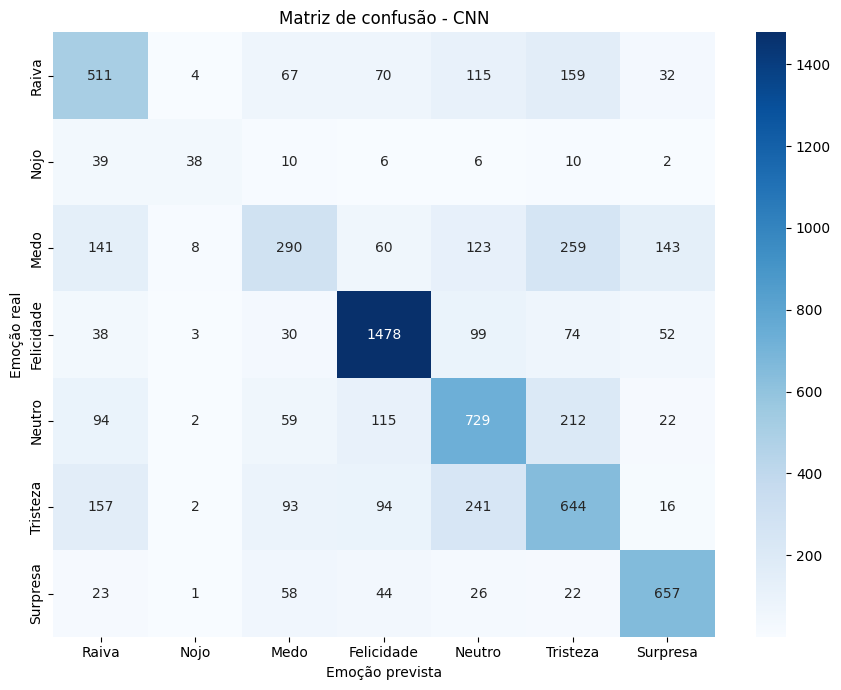

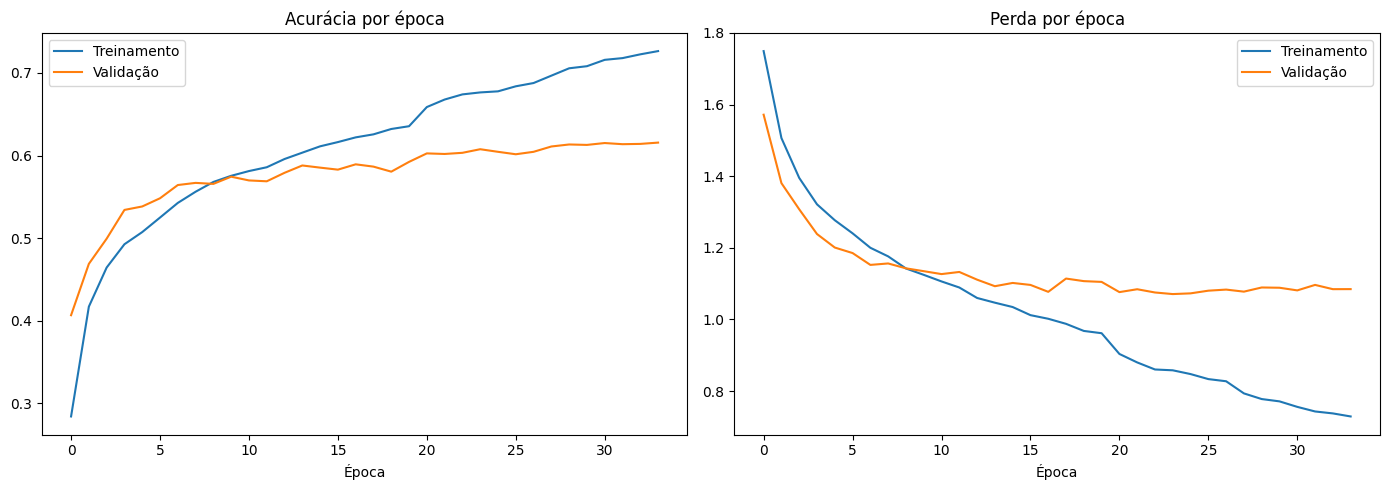

In [ ]:
# Avaliação final no conjunto de teste oficial
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Acurácia no teste: {test_accuracy:.4f}")
print(f"Perda no teste: {test_loss:.4f}")

y_pred = np.argmax(model.predict(X_test, batch_size=64), axis=1)
nomes_classes = ["Raiva", "Nojo", "Medo", "Felicidade", "Neutro", "Tristeza", "Surpresa"]
print(classification_report(y_test, y_pred, labels=list(range(7)), target_names=nomes_classes, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=list(range(7)))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=nomes_classes, yticklabels=nomes_classes)
plt.xlabel("Emoção prevista")
plt.ylabel("Emoção real")
plt.title("Matriz de confusão - CNN")
plt.tight_layout()
plt.show()

# Gráficos de treinamento e validação
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history["accuracy"], label="Treinamento")
axes[0].plot(history.history["val_accuracy"], label="Validação")
axes[0].set_title("Acurácia por época")
axes[0].set_xlabel("Época")
axes[0].legend()
axes[1].plot(history.history["loss"], label="Treinamento")
axes[1].plot(history.history["val_loss"], label="Validação")
axes[1].set_title("Perda por época")
axes[1].set_xlabel("Época")
axes[1].legend()
plt.tight_layout()
plt.show()